### ML Lifecycle

1. Business Understanding
2. Data Collection
3. Data Understanding
4. Data Preparation
5. Model Building
6. Model Training
7. Model Testing
8. Model Evaluation
9. Model Deployment
10. CI / CD


In [ ]:
pip install scikit-learn

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

# Data Collection
cars_data = pd.read_csv('mtcars.csv')
cars_data

# Data Understanding
cars_data.shape #(32, 12)
cars_data.isna().sum()
cars_data.dtypes
cars_data.duplicated()
cars_data.describe()
cars_data.info()
cars_data

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   model   32 non-null     str    
 1   mpg     32 non-null     float64
 2   cyl     32 non-null     int64  
 3   disp    32 non-null     float64
 4   hp      32 non-null     int64  
 5   drat    32 non-null     float64
 6   wt      32 non-null     float64
 7   qsec    32 non-null     float64
 8   vs      32 non-null     int64  
 9   am      32 non-null     int64  
 10  gear    32 non-null     int64  
 11  carb    32 non-null     int64  
dtypes: float64(5), int64(6), str(1)
memory usage: 3.1 KB


,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
5,Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
6,Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
7,Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
8,Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
9,Merc 280,19.2,6,167.6,123,3.92,3.440,18.30,1,0,4,4


### Check Assumptions

1. Linearity Test - Correlation Matix
2. Normality Test
3. Homoscadesticity Test
4. No Multocollinearity
5. No Auto Regression Test
6. Zero Residuel mean Test

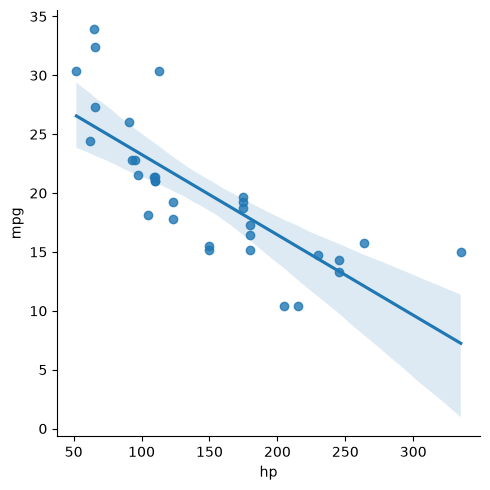

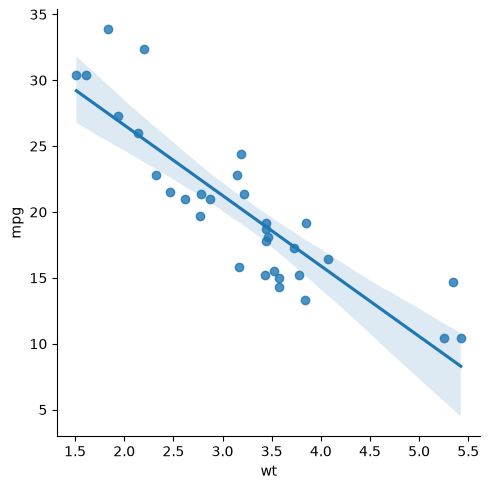

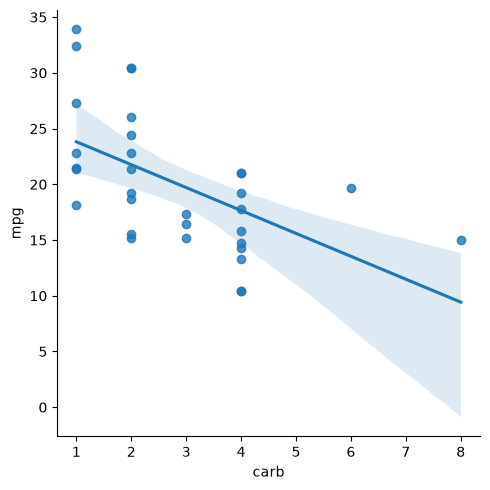

In [63]:
# 1 Linearity Test

sns.lmplot(data=cars_data, x='hp', y='mpg')
plt.show()

sns.lmplot(data=cars_data, x='wt', y='mpg')
plt.show()

sns.lmplot(data=cars_data, x='carb', y='mpg')
plt.show()

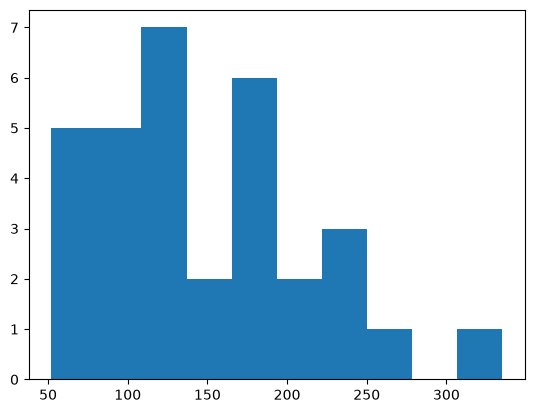

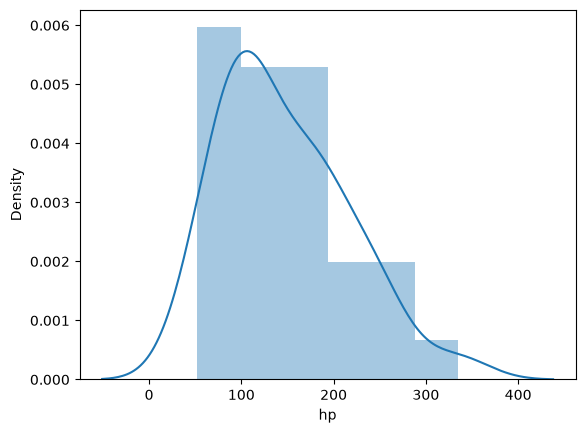

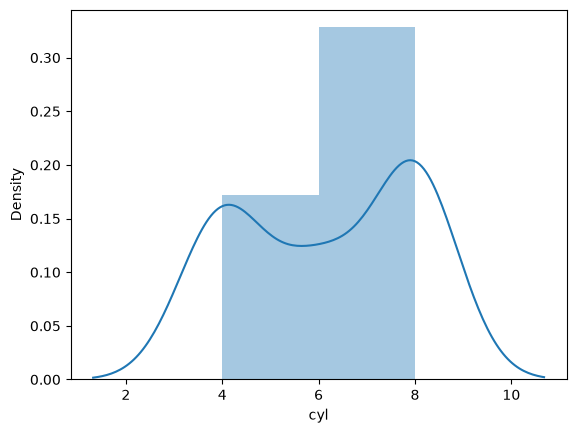

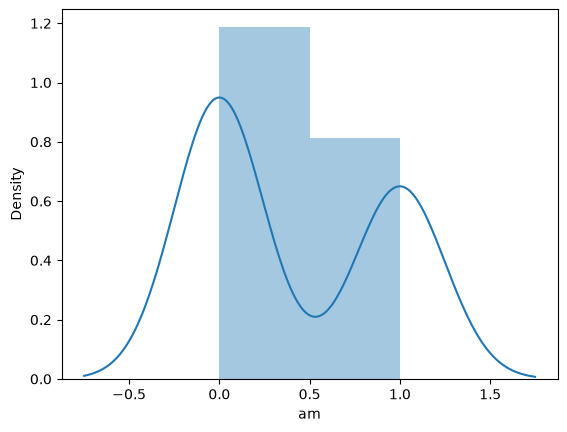

In [64]:
# 2 Normality Test

plt.hist(cars_data['hp'])
plt.show()

sns.distplot(cars_data['hp'])
plt.show()

sns.distplot(cars_data['cyl'])
plt.show()

sns.distplot(cars_data['am'])
plt.show()

<Axes: >

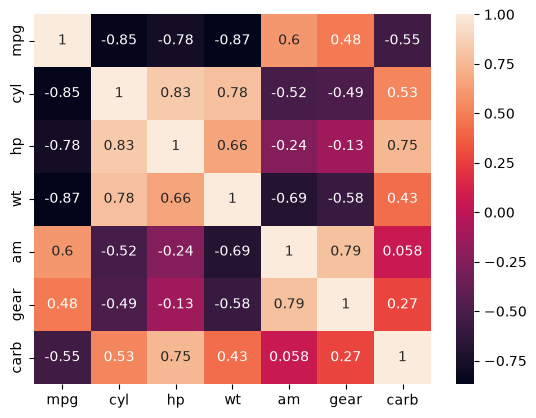

In [65]:
# 3 Correlation Test - Multi coleniarity
cars_data = cars_data[['mpg','cyl','hp','wt','am','gear','carb']]
cars_corr = cars_data.corr()

sns.heatmap(cars_corr, annot=True)

# No multicollinearity - Passed

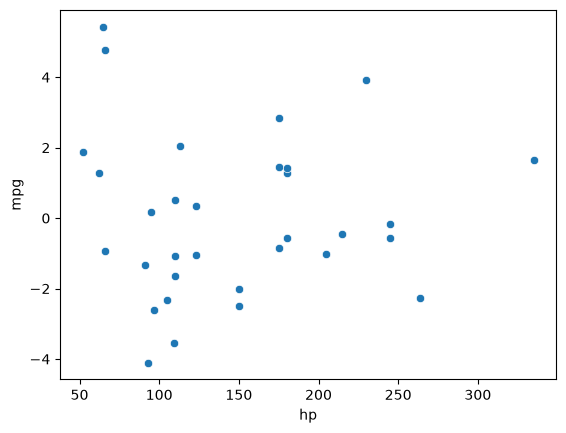

In [84]:
# 4 Homoscadesticity Test - After getting Model Evaluation

sns.scatterplot(cars_data, x='hp', y = error)
plt.show()

# Test Failed

In [ ]:
# 5 No Auto Regression Test

# Passed - No time related data in dataset

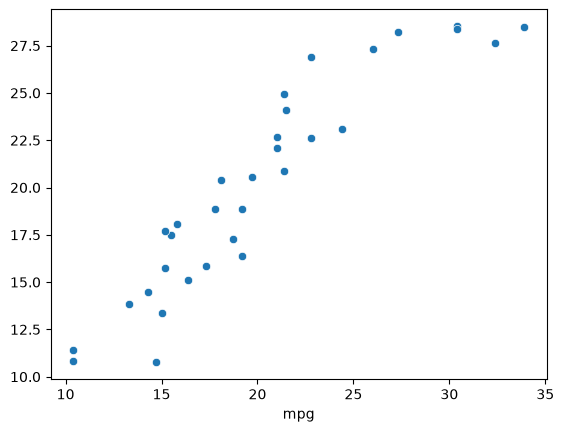

In [83]:
# 6 Zero Residuel mean Test - After getting Model Evaluation

sns.scatterplot(data=cars_data, x='mpg', y=y_pred)
plt.show()

# Test Failed

In [24]:
# Data Preparation

X = cars_data[['cyl','hp','wt','am','gear','carb']]
y = cars_data['mpg']

In [67]:
# Model Building

linear_model = LinearRegression()

In [78]:
# Model Training

linear_model.fit(X, y)

linear_model.coef_
linear_model.intercept_

np.float64(32.661867922243275)

In [75]:
# Model Testing

y_pred = linear_model.predict(X)
y_pred

array([22.64575155, 22.07852371, 26.90414418, 20.87736555, 17.25818178,
       20.41869204, 14.45971119, 23.10887529, 22.62820551, 18.85265196,
       18.85265196, 15.12000818, 15.87631196, 15.76509082, 11.41316155,
       10.85349176, 10.77029085, 27.63714949, 28.52962811, 28.46632587,
       24.11626918, 17.51177848, 17.70085442, 13.85911701, 16.35729051,
       28.22662156, 27.34020633, 28.35515502, 18.06940661, 20.54072166,
       13.35212566, 24.95424023])

In [76]:
# Model Evaluation

error = y - y_pred
error

0    -1.645752
1    -1.078524
2    -4.104144
3     0.522634
4     1.441818
5    -2.318692
6    -0.159711
7     1.291125
8     0.171794
9     0.347348
10   -1.052652
11    1.279992
12    1.423688
13   -0.565091
14   -1.013162
15   -0.453492
16    3.929709
17    4.762851
18    1.870372
19    5.433674
20   -2.616269
21   -2.011778
22   -2.500854
23   -0.559117
24    2.842709
25   -0.926622
26   -1.340206
27    2.044845
28   -2.269407
29   -0.840722
30    1.647874
31   -3.554240
Name: mpg, dtype: float64

In [81]:
# Model Deployment

from pickle import dump, load

dump(obj= linear_model, file= open(file='linear_intel.pkl', mode='wb'))

linear_pkl = load(file= open(file='linear_intel.pkl', mode='rb'))

linear_pkl.predict(X)



array([22.64575155, 22.07852371, 26.90414418, 20.87736555, 17.25818178,
       20.41869204, 14.45971119, 23.10887529, 22.62820551, 18.85265196,
       18.85265196, 15.12000818, 15.87631196, 15.76509082, 11.41316155,
       10.85349176, 10.77029085, 27.63714949, 28.52962811, 28.46632587,
       24.11626918, 17.51177848, 17.70085442, 13.85911701, 16.35729051,
       28.22662156, 27.34020633, 28.35515502, 18.06940661, 20.54072166,
       13.35212566, 24.95424023])